# SP-2 — Modelos de contagem: Poisson vs binomial negativa (offset)

**Squad Inteligência · spike de 1 dia · Sprint 0**

**Pergunta:** quando o alvo é uma contagem de casos por bairro × semana, quando o Poisson deixa de ser adequado e como o offset de população entra no modelo interpretável?

**Aceite:** GLM rodando no painel 2024–25 + resumo de 1 página para o orientador.

**Dados:** painel bairro × SE (US14), 2024–2025, gerado por `backend/scripts/gerar_painel.py`.
**População:** placeholder opção A (US08 pendente) — ver `_comum.carregar_populacao()`.


In [1]:
%matplotlib inline
import sys
from pathlib import Path

for candidato in (Path.cwd(), Path.cwd() / "backend" / "notebooks"):
    if (candidato / "_comum.py").exists():
        sys.path.insert(0, str(candidato))
        break
else:
    raise RuntimeError("Rode o notebook em backend/notebooks ou na raiz do repo")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import _comum

_comum.SAIDAS_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
np.random.seed(42)
print("saídas em", _comum.SAIDAS_DIR)
import statsmodels.api as sm


saídas em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas


## 1. Dados e recorte

O painel já traz casos e clima por semana epidemiológica, além das features defasadas. Vamos usar somente linhas com alvo e covariáveis completos — ausência de cobertura é um estado legítimo e **não** é imputada.


In [2]:
painel = _comum.carregar_painel(anos=[2024, 2025])
print("linhas:", len(painel), "| bairros:", painel.bairro.nunique(), "| semanas:", painel.semana.nunique())
display(painel[["bairro", "ds", "semana", "casos", "chuva_mm", "temp_media"]].head())

print("\nCasos por ano:")
display(painel.assign(ano=painel.semana.floordiv(100)).groupby("ano").casos.agg(["sum", "mean", "max"]).round(2))

print("\nNaN nas colunas usadas:")
display(painel[["casos", "chuva_lag2", "chuva_roll4", "temp_media", "sin_woy", "cos_woy"]].isna().sum().to_frame("n_nan"))

linhas: 9870 | bairros: 94 | semanas: 105


,bairro,ds,semana,casos,chuva_mm,temp_media
0,AFLITOS,3,202401,NaN,NaN,NaN
1,AFLITOS,3,202402,0.0,25.95,27.200000
2,AFLITOS,3,202403,0.0,44.70,27.528571
3,AFLITOS,3,202404,0.0,17.30,28.242857
4,AFLITOS,3,202405,0.0,3.87,27.828571



Casos por ano:


,sum,mean,max
ano,,,
2024,9716.0,2.03,63.0
2025,8547.0,1.75,25.0



NaN nas colunas usadas:


,n_nan
casos,188
chuva_lag2,282
chuva_roll4,470
temp_media,94
sin_woy,0
cos_woy,0


## 2. Desenho do modelo

Para cada bairro $i$ e semana $t$:

$$
\log E[Y_{it}] = \beta_0 + \beta_1\,chuva_{t-2} + \beta_2\,chuva\_roll4_t + \beta_3\,temp_t + \beta_4\sin(SE_t) + \beta_5\cos(SE_t) + \log(pop_i)
$$

- **Poisson:** $Var(Y) = E[Y]$ (equidispersão).
- **Binomial negativa NB2:** $Var(Y) = E[Y] + \alpha E[Y]^2$, com $\alpha$ estimado por máxima verossimilhança.
- O **offset** $\log(pop_i)$ transforma a média de contagens em taxa por habitante. Com população constante (placeholder), ele apenas desloca o intercepto — a comparação entre famílias não muda.
- A validação é temporal simples: treina em 2024, testa em 2025. O esquema rolling-origin completo é o SP-3 (João Rafael).


In [3]:
cols_features = ["chuva_lag2", "chuva_roll4", "temp_media", "sin_woy", "cos_woy"]
df = painel.dropna(subset=["casos", *cols_features]).copy()

pop = _comum.carregar_populacao()
df = df.merge(pop[["key", "populacao", "fonte"]], left_on="bairro_norm", right_on="key", how="left")
df["offset"] = np.log(df["populacao"])

X = sm.add_constant(df[cols_features], has_constant="add")
y = df["casos"].astype(float)

print("linhas no modelo:", len(df), "| bairros:", df.bairro.nunique())
print("fonte da população:", df["fonte"].unique().tolist())
print("valores únicos de offset:", df["offset"].unique().tolist())
display(df[cols_features + ["casos"]].describe().round(3))

linhas no modelo: 9306 | bairros: 94
fonte da população: ['placeholder_opcao_A (US08 pendente)']
valores únicos de offset: [0.0]


,chuva_lag2,chuva_roll4,temp_media,sin_woy,cos_woy,casos
count,9306.000,9306.000,9306.000,9306.000,9306.000,9306.000
mean,27.316,110.237,26.040,-0.018,-0.047,1.937
std,34.274,96.155,1.178,0.719,0.693,3.530
min,0.067,3.570,23.986,-1.000,-1.000,0.000
25%,3.285,35.737,24.900,-0.749,-0.749,0.000
50%,14.600,81.572,26.286,-0.121,-0.121,1.000
75%,42.535,171.030,27.086,0.749,0.663,2.000
max,186.699,382.603,28.500,1.000,1.000,63.000


## 3. Poisson

In [4]:
poisson = sm.GLM(y, X, family=sm.families.Poisson(), offset=df["offset"]).fit()
print(f"Poisson: llf={poisson.llf:.2f} | AIC={poisson.aic:.2f} | BIC={poisson.bic_llf:.2f}")
display(poisson.summary().tables[1])

Poisson: llf=-25007.61 | AIC=50027.22 | BIC=50070.05


,coef,std err,z,P>|z|,[0.025,0.975]
const,0.5343,0.422,1.266,0.205,-0.293,1.362
chuva_lag2,0.0011,0.000,3.811,0.000,0.001,0.002
chuva_roll4,-0.0004,0.000,-2.884,0.004,-0.001,-0.000
temp_media,0.0043,0.016,0.270,0.787,-0.027,0.035
sin_woy,0.2991,0.022,13.341,0.000,0.255,0.343
cos_woy,-0.1427,0.017,-8.161,0.000,-0.177,-0.108


In [5]:
disp_pearson = poisson.pearson_chi2 / poisson.df_resid
print(f"Dispersão de Pearson (chi2/gl): {disp_pearson:.2f}")
print("Leitura: ~1 = equidispersão (Poisson aceitável); > 1,5 = sobredispersão (NB necessária).")
print("Fração de observações com zero casos:", f"{(y == 0).mean():.1%}")
print("Média e variância dos casos:", f"média={y.mean():.2f} | variância={y.var():.2f}")

Dispersão de Pearson (chi2/gl): 5.87
Leitura: ~1 = equidispersão (Poisson aceitável); > 1,5 = sobredispersão (NB necessária).
Fração de observações com zero casos: 43.4%
Média e variância dos casos: média=1.94 | variância=12.46


## 4. Binomial negativa (NB2)

In [6]:
nb = sm.NegativeBinomial(y, X, offset=df["offset"]).fit(disp=0, maxiter=300)
print("convergiu:", nb.mle_retvals.get("converged"))
print(f"NB2: llf={nb.llf:.2f} | AIC={nb.aic:.2f} | BIC={nb.bic:.2f} | alpha={nb.params['alpha']:.4f}")
display(nb.summary().tables[1])

convergiu: True
NB2: llf=-16977.08 | AIC=33968.16 | BIC=34018.13 | alpha=1.8835


,coef,std err,z,P>|z|,[0.025,0.975]
const,-0.1250,1.003,-0.125,0.901,-2.090,1.840
chuva_lag2,0.0016,0.001,2.042,0.041,6.31e-05,0.003
chuva_roll4,-0.0002,0.000,-0.640,0.522,-0.001,0.000
temp_media,0.0283,0.038,0.747,0.455,-0.046,0.102
sin_woy,0.2366,0.050,4.725,0.000,0.138,0.335
cos_woy,-0.1838,0.044,-4.160,0.000,-0.270,-0.097
alpha,1.8835,0.042,44.590,0.000,1.801,1.966


## 5. Comparação direta

In [7]:
comparacao = pd.DataFrame({
    "modelo": ["Poisson", "Binomial negativa (NB2)"],
    "log_verossimilhanca": [poisson.llf, nb.llf],
    "AIC": [poisson.aic, nb.aic],
    "BIC": [poisson.bic_llf, nb.bic],
    "alpha": [np.nan, nb.params["alpha"]],
    "dispersao_pearson": [disp_pearson, np.nan],
}).round(3)
display(comparacao)
comparacao.to_csv(_comum.SAIDAS_DIR / "sp2_comparacao_modelos.csv", index=False)

,modelo,log_verossimilhanca,AIC,BIC,alpha,dispersao_pearson
0,Poisson,-25007.610,50027.220,50070.051,NaN,5.868
1,Binomial negativa (NB2),-16977.078,33968.156,34018.125,1.884,NaN


### Checagem do offset

Com população constante, multiplicar a população por uma constante $c$ desloca o intercepto em $-\log c$ e **não altera** os demais coeficientes nem o ajuste. É exatamente o que acontece enquanto a US08 não chega.


In [8]:
c = 1000.0
pois_c = sm.GLM(y, X, family=sm.families.Poisson(), offset=df["offset"] + np.log(c)).fit()
dif = (pois_c.params - poisson.params).abs()
print(f"Deslocamento esperado do intercepto: -log({c:.0f}) = {-np.log(c):.4f}")
print("Diferença observada no intercepto:", round(dif["const"], 6))
print("Maior diferença nos demais coeficientes:", round(dif.drop("const").max(), 8))
print("AIC com offset original:", round(poisson.aic, 3), "| com offset x1000:", round(pois_c.aic, 3))

Deslocamento esperado do intercepto: -log(1000) = -6.9078
Diferença observada no intercepto: 6.907755
Maior diferença nos demais coeficientes: 0.0
AIC com offset original: 50027.22 | com offset x1000: 50027.22


## 6. Validação temporal: treino 2024 → teste 2025

Esta não é a validação final do projeto — é uma checagem rápida de que o modelo aprendido em um ano não desaba no ano seguinte. O rolling-origin por temporada entra no SP-3 e na US26.


In [9]:
treino = df["semana"].floordiv(100) == 2024
teste = ~treino

X_tr, X_te = X[treino], X[teste]
y_tr, y_te = y[treino], y[teste]
o_tr, o_te = df.loc[treino, "offset"], df.loc[teste, "offset"]

pois_tr = sm.GLM(y_tr, X_tr, family=sm.families.Poisson(), offset=o_tr).fit()
nb_tr = sm.NegativeBinomial(y_tr, X_tr, offset=o_tr).fit(disp=0, maxiter=300)

pred_pois = pois_tr.predict(X_te, offset=o_te)
pred_nb = nb_tr.predict(X_te, offset=o_te)


def metricas(obs, pred):
    erro = np.asarray(obs) - np.asarray(pred)
    return {
        "MAE": float(np.mean(np.abs(erro))),
        "RMSE": float(np.sqrt(np.mean(erro ** 2))),
        "spearman": float(pd.Series(np.asarray(obs)).corr(pd.Series(np.asarray(pred)), method="spearman")),
    }


val = pd.DataFrame({
    "Poisson": metricas(y_te, pred_pois),
    "Binomial negativa": metricas(y_te, pred_nb),
}).T.round(4)
print("Treino: 2024 | Teste: 2025")
display(val)
val.to_csv(_comum.SAIDAS_DIR / "sp2_validacao_temporal.csv")

Treino: 2024 | Teste: 2025


,MAE,RMSE,spearman
Poisson,2.3843,3.3186,-0.1338
Binomial negativa,2.2791,3.1958,-0.1265


figura salva em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp2_ajuste_2025.png


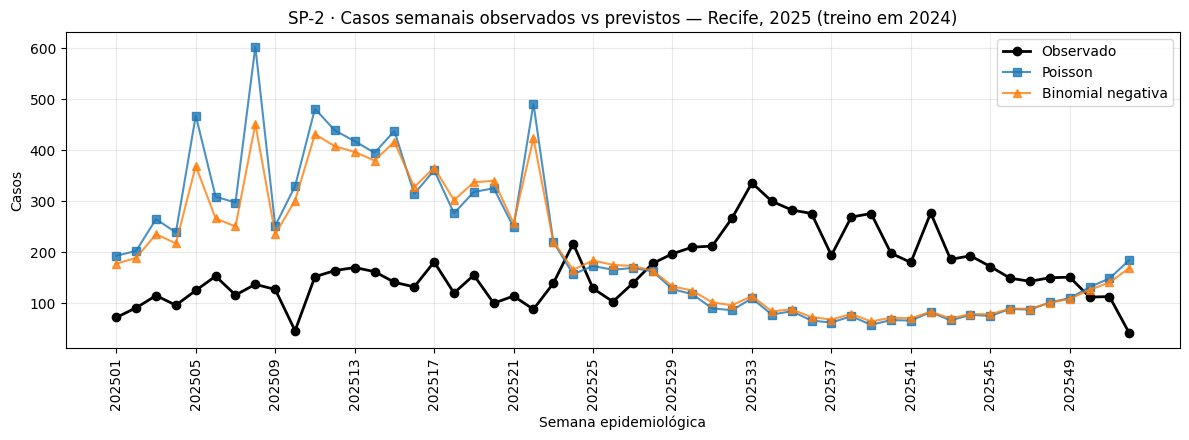

In [10]:
fig, ax = plt.subplots(figsize=(12, 4.5))
obs_semana = y_te.groupby(df.loc[teste, "semana"]).sum()
pois_semana = pd.Series(pred_pois.values, index=df.loc[teste, "semana"].values).groupby(level=0).sum()
nb_semana = pd.Series(pred_nb.values, index=df.loc[teste, "semana"].values).groupby(level=0).sum()

ax.plot(obs_semana.index.astype(str), obs_semana.values, marker="o", color="black", linewidth=2, label="Observado")
ax.plot(pois_semana.index.astype(str), pois_semana.values, marker="s", alpha=0.8, label="Poisson")
ax.plot(nb_semana.index.astype(str), nb_semana.values, marker="^", alpha=0.8, label="Binomial negativa")
ax.set_title("SP-2 · Casos semanais observados vs previstos — Recife, 2025 (treino em 2024)")
ax.set_xlabel("Semana epidemiológica")
ax.set_ylabel("Casos")
ax.set_xticks(range(0, len(obs_semana), 4))
ax.set_xticklabels(obs_semana.index.astype(str)[::4], rotation=90)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
caminho = _comum.salvar_figura(fig, "sp2_ajuste_2025.png")
print("figura salva em", caminho)
plt.show()

## 7. Interpretação dos coeficientes (NB)

Coeficientes em escala log; `IRR = exp(coef)` é a razão de taxas para +1 unidade da covariável (ou +1 mm de chuva).


In [11]:
ic = nb.conf_int()
params = pd.DataFrame({
    "coef": nb.params,
    "IC95_inf": ic[0],
    "IC95_sup": ic[1],
})
params["IRR"] = np.exp(params["coef"])
params["IRR_inf"] = np.exp(params["IC95_inf"])
params["IRR_sup"] = np.exp(params["IC95_sup"])
params = params.drop(index="alpha").round(4)
display(params)
params.to_csv(_comum.SAIDAS_DIR / "sp2_coeficientes_nb.csv")

,coef,IC95_inf,IC95_sup,IRR,IRR_inf,IRR_sup
const,-0.1250,-2.0905,1.8405,0.8825,0.1236,6.2995
chuva_lag2,0.0016,0.0001,0.0031,1.0016,1.0001,1.0031
chuva_roll4,-0.0002,-0.0009,0.0005,0.9998,0.9991,1.0005
temp_media,0.0283,-0.0459,0.1024,1.0287,0.9552,1.1078
sin_woy,0.2366,0.1385,0.3347,1.2669,1.1485,1.3976
cos_woy,-0.1838,-0.2704,-0.0972,0.8321,0.7631,0.9074


figura salva em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp2_irr_nb.png


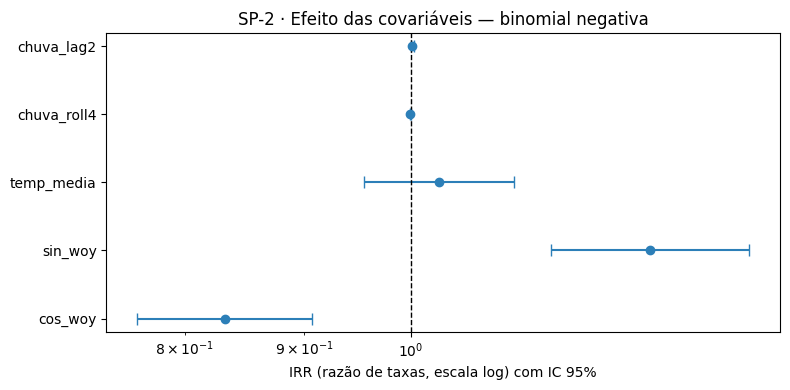

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
ordem = params.drop(index="const").index[::-1]
ypos = np.arange(len(ordem))
ax.errorbar(
    params.loc[ordem, "IRR"], ypos,
    xerr=[params.loc[ordem, "IRR"] - params.loc[ordem, "IRR_inf"],
          params.loc[ordem, "IRR_sup"] - params.loc[ordem, "IRR"]],
    fmt="o", color="#2c7fb8", capsize=4,
)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yticks(ypos, ordem)
ax.set_xlabel("IRR (razão de taxas, escala log) com IC 95%")
ax.set_title("SP-2 · Efeito das covariáveis — binomial negativa")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
caminho = _comum.salvar_figura(fig, "sp2_irr_nb.png")
print("figura salva em", caminho)
plt.show()

## 8. Leitura e limitações

**Decisão esperada:** se a dispersão de Pearson for muito maior que 1, o Poisson subestima a incerteza e a binomial negativa é o modelo interpretável a levar para a US24.

Limitações explícitas:
- População é placeholder (opção A): o offset é 0 e a leitura é de **contagem**, não de taxa por 100 mil.
- Sem efeitos fixos de bairro: o modelo é pooled e não controla heterogeneidade não observada.
- Semana epidemiológica por `DT_NOTIFIC` (decisão de US01 ainda pendente); atraso de notificação não é modelado.
- Validação 2024→2025 é simples; não substitui rolling-origin.
- Correlação não é causal; os coeficientes descrevem associação no painel ecológico.


In [13]:
print("=== Resumo SP-2 ===")
print(f"Observações: {len(df):,} | bairros: {df.bairro.nunique()} | semanas: {df.semana.nunique()}")
print(f"Dispersão de Pearson (Poisson): {disp_pearson:.2f}")
print(f"alpha NB2: {nb.params['alpha']:.3f}")
print(f"AIC Poisson: {poisson.aic:,.0f} | AIC NB2: {nb.aic:,.0f}")
print(f"MAE teste 2025 — Poisson: {val.loc['Poisson','MAE']:.3f} | NB: {val.loc['Binomial negativa','MAE']:.3f}")
print("Recomendação: binomial negativa NB2 com offset log(população) como GLM interpretável da US24.")

=== Resumo SP-2 ===
Observações: 9,306 | bairros: 94 | semanas: 99
Dispersão de Pearson (Poisson): 5.87
alpha NB2: 1.884
AIC Poisson: 50,027 | AIC NB2: 33,968
MAE teste 2025 — Poisson: 2.384 | NB: 2.279
Recomendação: binomial negativa NB2 com offset log(população) como GLM interpretável da US24.
